#### DATASET INVESTIGATION

In [23]:
import pandas as pd
import numpy as np

# Load dataset
df = pd.read_csv("train_labels.csv")

print(df["class"].nunique())
print(df["class"].unique())

print(df["image_id"].nunique())

print(df["class"].value_counts())


8
<StringArray>
[  'DogEye', 'DogMouth',  'DogFace',  'DogNose',  'CatNose',  'CatFace',
 'CatMouth',   'CatEye']
Length: 8, dtype: str
63660
class
CatEye      13884
DogEye      11580
CatNose      6942
CatFace      6942
CatMouth     6942
DogMouth     5790
DogFace      5790
DogNose      5790
Name: count, dtype: int64


In [7]:
import os
from PIL import Image 

folder_path = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train\train"

file_extension = ".jpg"

data_list = []

for filename in os.listdir(folder_path):
    if filename.lower().endswith(file_extension):
        file_path = os.path.join(folder_path, filename)
        try:
            file_size_bytes = os.path.getsize(file_path)
            file_size_mb = file_size_bytes / (1024)
            
           
            with Image.open(file_path) as img:
                width, height = img.size
            
       
            print(f"{filename:<30} | {file_size_mb:<15.2f} | {width}x{height}")
            data_list.append({
                'File Name': filename,
                'File Size (MB)': file_size_mb,
                'Width': width,
                'Height': height
            })
        except Exception as e:
            print(f"Could not process {filename}: {e}")


df = pd.DataFrame(data_list)

csv_output_path = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\image_size_data.csv"

df.to_csv(csv_output_path, index=False)
print(f"\nSuccessfully logged all data to {csv_output_path}")


00001.jpg                      | 1.45            | 36x36
00002.jpg                      | 23.40           | 214x157
00003.jpg                      | 6.55            | 97x97
00004.jpg                      | 5.47            | 110x110
00005.jpg                      | 1.69            | 42x42
00006.jpg                      | 1.35            | 28x28
00007.jpg                      | 14.88           | 182x135
00008.jpg                      | 6.09            | 128x128
00009.jpg                      | 90.48           | 343x376
00010.jpg                      | 1.25            | 36x36
00011.jpg                      | 10.92           | 149x148
00012.jpg                      | 4.82            | 94x70
00013.jpg                      | 3.57            | 98x68
00014.jpg                      | 21.20           | 188x182
00015.jpg                      | 13.14           | 158x158
00016.jpg                      | 11.54           | 140x140
00017.jpg                      | 2.30            | 66x66
00018.jpg    

=== FILE SIZE ===
Average: 10.61
Largest: 1233.08
Smallest: 0.64

=== IMAGE DIMENSIONS ===
Average width:  113 px
Average height: 110 px
Largest width:  2219 px
Largest height: 2219 px
Average total pixels: 22026
Largest total pixels: 4923961

=== LARGEST FILES ===
       File Size (kB)  Width  Height
8325      1233.079102   2219    2219
47667      976.843750   2190    2070
7890       780.717773   1429    1429
16819      747.480469   1791    1736
44618      742.433594   1719    1720
10529      685.170898   1623    1624
9071       643.545898   1424    1425
55653      631.757812   1383    1384
52413      628.821289   1786    1787
539        554.873047   1281    1280

=== LARGEST DIMENSIONS ===
       Width  Height  total_pixels  File Size (kB)
8325    2219    2219       4923961     1233.079102
47667   2190    2070       4533300      976.843750
2694    1873    1873       3508129      504.759766
52413   1786    1787       3191582      628.821289
16819   1791    1736       3109176      747.

C:\Users\wah31\AppData\Local\Temp\ipykernel_23808\1091523208.py:63: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(
C:\Users\wah31\AppData\Local\Temp\ipykernel_23808\1091523208.py:81: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(


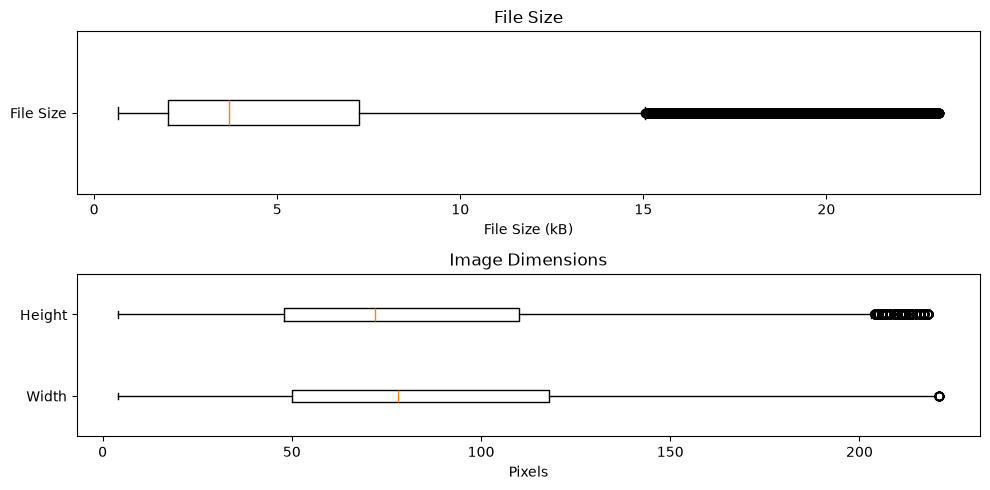

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# Load CSV
df = pd.read_csv("image_size_data.csv")


# Summary statistics


print("=== FILE SIZE ===")
print(f"Average: {df['File Size (kB)'].mean():.2f}")
print(f"Largest: {df['File Size (kB)'].max():.2f}")
print(f"Smallest: {df['File Size (kB)'].min():.2f}")

print("\n=== IMAGE DIMENSIONS ===")
print(f"Average width:  {df['Width'].mean():.0f} px")
print(f"Average height: {df['Height'].mean():.0f} px")
print(f"Largest width:  {df['Width'].max():.0f} px")
print(f"Largest height: {df['Height'].max():.0f} px")

# Total pixels
df["total_pixels"] = df["Width"] * df["Height"]

print(f"Average total pixels: {df['total_pixels'].mean():.0f}")
print(f"Largest total pixels: {df['total_pixels'].max():.0f}")



# Largest files


print("\n=== LARGEST FILES ===")

largest_files = df.sort_values(
    by="File Size (kB)",
    ascending=False
)

print(largest_files[["File Size (kB)", "Width", "Height"]].head(10))



# Largest dimensions


print("\n=== LARGEST DIMENSIONS ===")

largest_dimensions = df.sort_values(
    by="total_pixels",
    ascending=False
)

print(largest_dimensions[["Width", "Height", "total_pixels", "File Size (kB)"]].head(10))


file_size = df["File Size (kB)"].dropna()
file_size_95 = file_size[file_size <= file_size.quantile(0.90)]

fig, axes = plt.subplots(2, 1, figsize=(10, 5))

# File size
axes[0].boxplot(
    file_size_95,
    vert=False
)

axes[0].set_title("File Size")
axes[0].set_xlabel("File Size (kB)")
axes[0].set_yticks([1])
axes[0].set_yticklabels(["File Size"])

width = df["Width"].dropna()
height = df["Height"].dropna()

width_95 = width[width <= width.quantile(0.90)]
height_95 = height[height <= height.quantile(0.90)]


# Image dimensions: width + height
axes[1].boxplot(
    [
        width_95,
        height_95
    ],
    vert=False
)

axes[1].set_title("Image Dimensions")
axes[1].set_xlabel("Pixels")
axes[1].set_yticks([1, 2])
axes[1].set_yticklabels(["Width", "Height"])


plt.tight_layout()
plt.show()

In [37]:
import pandas as pd

df = pd.read_csv("image_size_data.csv")

small_images = df[(df["Width"] < 10) | (df["Height"] < 10)]

for filename in small_images["File Name"]:
    print(filename)

00119.jpg
01594.jpg
02188.jpg
02480.jpg
05361.jpg
10106.jpg
12429.jpg
13563.jpg
14181.jpg
21923.jpg
29282.jpg
29753.jpg
32523.jpg
36018.jpg
38794.jpg
39855.jpg
43884.jpg
51449.jpg
52816.jpg
59018.jpg
60897.jpg


In [40]:
import pandas as pd

LABELS_FILE = "train_labels.csv"
METADATA_FILE = "image_size_data.csv"

labels = pd.read_csv(LABELS_FILE)
metadata = pd.read_csv(METADATA_FILE)

labels["image_id"] = labels["image_id"].astype(str).str.strip()

metadata["image_id"] = (
    metadata["File Name"]
    .astype(str)
    .str.extract(r"(\d+)", expand=False)
)

# Convert both to integers so they match correctly
labels["image_id"] = pd.to_numeric(
    labels["image_id"],
    errors="coerce"
)

metadata["image_id"] = pd.to_numeric(
    metadata["image_id"],
    errors="coerce"
)

df = pd.merge(
    labels,
    metadata,
    on="image_id",
    how="inner",
    validate="one_to_one"
)

df["MinDim"] = df[["Width", "Height"]].min(axis=1)

df["AspectRatio"] = (
    df["Width"] / df["Height"]
)

df = df[
    [
        "image_id",
        "class",
        "File Name",
        "File Size (kB)",
        "Width",
        "Height",
        "MinDim",
        "AspectRatio"
    ]
]

OUTPUT_FILE = "dataset_audit.csv"

df.to_csv(
    OUTPUT_FILE,
    index=False
)

print(f"\nSaved successfully to: {OUTPUT_FILE}")


Saved successfully to: dataset_audit.csv


In [43]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

df = pd.read_csv("dataset_audit.csv")

features = [
    "Width",
    "Height",
    "MinDim",
    "AspectRatio",
    "File Size (kB)"
]

X = df[features]
y = df["class"]


X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("\nTrain size:", len(X_train))
print("Validation size:", len(X_val))

rf = RandomForestClassifier(
    n_estimators=400,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

print("\nTraining Random Forest...")

rf.fit(X_train, y_train)

print("Training complete.")

y_pred = rf.predict(X_val)


accuracy = accuracy_score(
    y_val,
    y_pred
)

macro_f1 = f1_score(
    y_val,
    y_pred,
    average="macro"
)

weighted_f1 = f1_score(
    y_val,
    y_pred,
    average="weighted"
)


print("RANDOM FOREST RESULTS")


print(f"Accuracy:     {accuracy:.4f}")
print(f"Accuracy:     {accuracy * 100:.2f}%")
print(f"Macro F1:     {macro_f1:.4f}")
print(f"Weighted F1:  {weighted_f1:.4f}")


print("\n")
print("CLASSIFICATION REPORT")


print(
    classification_report(
        y_val,
        y_pred,
        digits=4
    )
)

classes = sorted(y.unique())

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=classes
)

cm_df = pd.DataFrame(
    cm,
    index=classes,
    columns=classes
)

print("\n")
print("CONFUSION MATRIX")
print("=")

print("Rows = Actual")
print("Columns = Predicted\n")

print(cm_df)

importance = pd.DataFrame({
    "Feature": features,
    "Importance": rf.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print("\n")
print("FEATURE IMPORTANCE")


print(
    importance.to_string(index=False)
)

results = df.loc[
    X_val.index,
    [
        "image_id",
        "File Name",
        "class",
        "Width",
        "Height",
        "MinDim",
        "AspectRatio",
        "File Size (kB)"
    ]
].copy()

results["PredictedClass"] = y_pred

results["Correct"] = (
    results["class"] ==
    results["PredictedClass"]
)

results.to_csv(
    "random_forest_metadata_predictions.csv",
    index=False
)

print(
    "\nPredictions saved to:"
    "\nrandom_forest_metadata_predictions.csv"
)

print("\nDone.")


Train size: 50928
Validation size: 12732

Training Random Forest...
Training complete.
RANDOM FOREST RESULTS
Accuracy:     0.5512
Accuracy:     55.12%
Macro F1:     0.5965
Weighted F1:  0.5528


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      CatEye     0.4617    0.3194    0.3776      2777
     CatFace     0.9292    0.9640    0.9463      1388
    CatMouth     0.9885    0.9928    0.9907      1388
     CatNose     0.1729    0.2066    0.1883      1389
      DogEye     0.3833    0.3325    0.3561      2316
     DogFace     0.6571    0.7876    0.7164      1158
    DogMouth     0.9939    0.9905    0.9922      1158
     DogNose     0.1693    0.2582    0.2045      1158

    accuracy                         0.5512     12732
   macro avg     0.5945    0.6064    0.5965     12732
weighted avg     0.5639    0.5512    0.5528     12732



CONFUSION MATRIX
=
Rows = Actual
Columns = Predicted

          CatEye  CatFace  CatMouth  CatNose  DogEye  DogFace  DogMouth  \


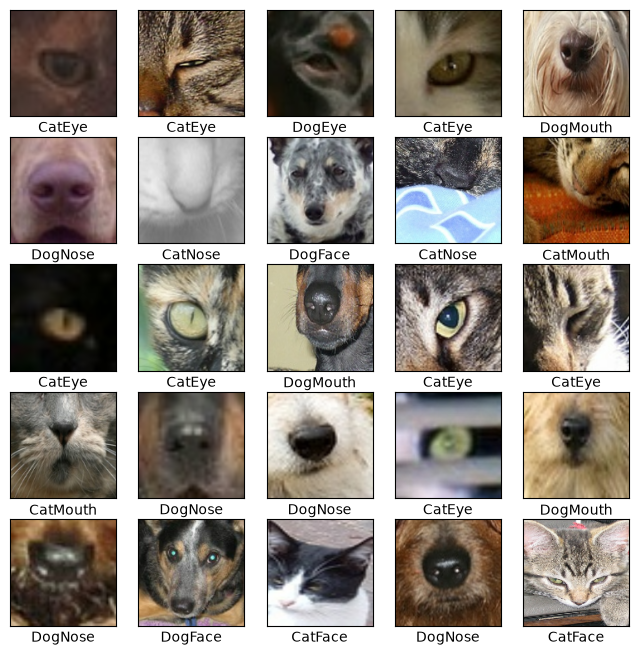

c:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 50176)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     3,211,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,268,168 (12.47 MB)

 Trainable params: 3,268,168 (12.47 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


c:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 231s 144ms/step - accuracy: 0.8738 - loss: 0.3754 - val_accuracy: 0.9453 - val_loss: 0.1715
Epoch 2/10
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 253s 159ms/step - accuracy: 0.9596 - loss: 0.1239 - val_accuracy: 0.9537 - val_loss: 0.1505
Epoch 3/10
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 248s 156ms/step - accuracy: 0.9728 - loss: 0.0786 - val_accuracy: 0.9477 - val_loss: 0.1967
Epoch 4/10
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 245s 154ms/step - accuracy: 0.9790 - loss: 0.0585 - val_accuracy: 0.9533 - val_loss: 0.1991
Epoch 5/10
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 255s 160ms/step - accuracy: 0.9844 - loss: 0.0462 - val_accuracy: 0.9594 - val_loss: 0.1764
Epoch 6/10
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 252s 158ms/step - accuracy: 0.9880 - loss: 0.0350 - val_accuracy: 0.9581 - val_loss: 0.1971
Epoch 7/10
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 249s 156ms/step - accuracy: 0.9907 - loss: 0.0293 - val_accuracy: 0.9583 - val_loss: 0.1995
Epoch 8/10
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 255s 152ms/step - accuracy: 0.9

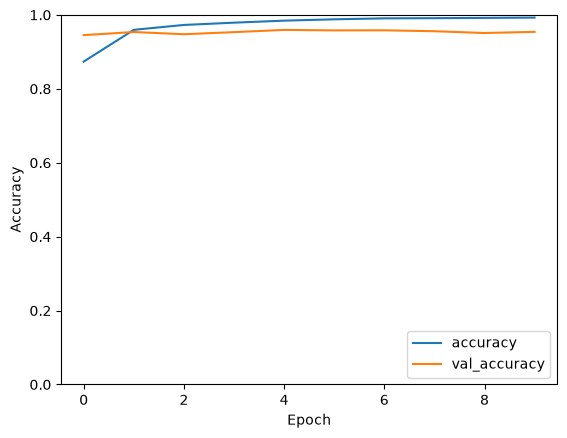

398/398 - 18s - 45ms/step - accuracy: 0.9541 - loss: 0.2705
Test Accuracy is 0.9541313052177429


In [ ]:
# Import TensorFlow
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

import os
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import load_img, img_to_array

#Load Data set 

label_csv = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\animal_facial_recognition\train_labels.csv"
training_images = r"C:\Users\wah31\OneDrive\Documents\Data_Ai_Kaggle\enge-707-2026-s-2-cat-and-dog-facial-feature-classification-ch\train\train"


df = pd.read_csv(label_csv, dtype={'image_id': str})

class_names = [
    'CatEye',
    'DogEye',
    'CatFace',
    'DogFace',
    'CatMouth',
    'DogMouth',
    'CatNose',
    'DogNose'
]

class_to_number = {
    name: i for i, name in enumerate(class_names)
}

df['label'] = df['class'].map(class_to_number)

train_df, test_df = train_test_split(
    df,
    test_size=0.2,
    random_state=123,
    stratify=df['label']
)

IMAGE_SIZE = (128, 128)

def load_image(image_id, label):
    image_path = tf.strings.join([
        training_images,
        os.sep,
        image_id,
        '.jpg'
    ])

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMAGE_SIZE)
    image = image / 255.0

    return image, label

train_dataset = tf.data.Dataset.from_tensor_slices(
    (
        train_df['image_id'].values,
        train_df['label'].values
    )
)

test_dataset = tf.data.Dataset.from_tensor_slices(
    (
        test_df['image_id'].values,
        test_df['label'].values
    )
)

train_dataset = train_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_dataset = test_dataset.map(
    load_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

BATCH_SIZE = 32

train_dataset = train_dataset.batch(BATCH_SIZE)
test_dataset = test_dataset.batch(BATCH_SIZE)

train_dataset = train_dataset.prefetch(tf.data.AUTOTUNE)
test_dataset = test_dataset.prefetch(tf.data.AUTOTUNE)

plt.figure(figsize=(8, 8))

for images, labels in train_dataset.take(1):
    for i in range(min(25, len(images))):
        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(images[i])
        plt.xlabel(class_names[labels[i]])

plt.show()


model = models.Sequential()
model.add(layers.Conv2D(
    32,
    (3, 3),
    activation='relu',
    input_shape=(128, 128, 3)
))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(
    64,
    (3, 3),
    activation='relu'
))
model.add(layers.MaxPooling2D((2, 2)))
model.add(layers.Conv2D(
    64,
    (3, 3),
    activation='relu'
))
model.add(layers.Flatten())
model.add(layers.Dense(
    64,
    activation='relu'
))
model.add(layers.Dense(8))
model.summary()

model.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(
        from_logits=True
    ),
    metrics=['accuracy']
)

history = model.fit(
    train_dataset,
    epochs=10,
    validation_data=test_dataset
)

plt.plot(
    history.history['accuracy'],
    label='accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='val_accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')

plt.show()

test_loss, test_acc = model.evaluate(
    test_dataset,
    verbose=2
)

print('Test Accuracy is', test_acc)


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense, Conv2D, BatchNormalization, Activation
from tensorflow.keras.layers import AveragePooling2D, Input, Flatten, Add
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, LearningRateScheduler, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.regularizers import l2
from tensorflow.keras.models import Model

import numpy as np
import os
import importlib

import image_preprocessing
importlib.reload(image_preprocessing)


batch_size = 32
epochs = 200
data_augmentation = True
num_classes = 8
subtract_pixel_mean = True


version = 2
n = 3
depth = n * 9 + 2

model_type = 'ResNet %dv%d' % (depth, version)

train_dataset, validation_dataset = image_preprocessing.preprocessTrainingData()

def lr_schedule(epoch):
    lr = 1e-3
    if epoch > 180:
        lr *= 0.5e-3
    elif epoch > 160:
        lr *= 1e-3
    elif epoch > 120:
        lr *= 1e-2
    elif epoch > 80:
        lr *= 1e-1
    print('Learning rate:', lr)
    return lr


def resnet_layer(inputs,
                 num_filters=16,
                 kernel_size=3,
                 strides=1,
                 activation='relu',
                 batch_normalization=True,
                 conv_first=True):
    conv = Conv2D(num_filters,
                  kernel_size=kernel_size,
                  strides=strides,
                  padding='same',
                  kernel_initializer='he_normal',
                  kernel_regularizer=l2(1e-4))
    x = inputs
    if conv_first:
        x = conv(x)
        if batch_normalization:
            x = BatchNormalization()(x)
        if activation is not None:
            x = Activation(activation)(x)
    else:
        if batch_normalization:
            x = BatchNormalization()(x)
        if activation is not None:
            x = Activation(activation)(x)
        x = conv(x)
    return x

input_shape = (128, 128, 3)

def resnet_v2(input_shape, depth, num_classes=8):
    if (depth - 2) % 9 != 0:
        raise ValueError('depth should be 9n + 2')

    data_augmentation = keras.Sequential([
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomRotation(0.1),
    keras.layers.RandomZoom(0.1),
    ])  

    num_filters_in = 16
    num_res_blocks = int((depth - 2) / 9)
    inputs = Input(shape=input_shape)
    x = data_augmentation(inputs)
    x = resnet_layer(x, num_filters=num_filters_in, conv_first=True)

    

    for stage in range(3):
        for res_block in range(num_res_blocks):
            activation = 'relu'
            batch_normalization = True
            strides = 1
            if stage == 0:
                num_filters_out = num_filters_in * 4
                if res_block == 0:
                    activation = None
                    batch_normalization = False
            else:
                num_filters_out = num_filters_in * 2
                if res_block == 0:
                    strides = 2
            y = resnet_layer(x, num_filters=num_filters_in, kernel_size=1,
                             strides=strides, activation=activation,
                             batch_normalization=batch_normalization, conv_first=False)
            y = resnet_layer(y, num_filters=num_filters_in, conv_first=False)
            y = resnet_layer(y, num_filters=num_filters_out, kernel_size=1, conv_first=False)
            if res_block == 0:
                x = resnet_layer(x, num_filters=num_filters_out, kernel_size=1,
                                 strides=strides, activation=None, batch_normalization=False)
            x = Add()([x, y])
        num_filters_in = num_filters_out

    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    x = keras.layers.GlobalAveragePooling2D()(x)
    outputs = Dense(
        num_classes,
        activation='softmax',
        kernel_initializer='he_normal'
    )(x)
    model = Model(inputs=inputs, outputs=outputs)
    return model


model = resnet_v2(input_shape=input_shape, depth=depth, num_classes=num_classes)


model.compile(loss='sparse_categorical_crossentropy',
              optimizer=Adam(learning_rate=lr_schedule(0)),
              metrics=['accuracy'])
model.summary()

history = model.fit(
    train_dataset,
    epochs = epochs,
    validation_data = validation_dataset,
    callbacks=callbacks
)

save_dir = os.path.join(os.getcwd(), 'saved_models')
model_name = 'cifar10_%s_model.{epoch:03d}.keras' % model_type
os.makedirs(save_dir, exist_ok=True)
filepath = os.path.join(save_dir, model_name)

checkpoint = ModelCheckpoint(filepath=filepath,
                             monitor='val_accuracy',
                             verbose=1,
                             save_best_only=True)
lr_scheduler = LearningRateScheduler(lr_schedule)
lr_reducer = ReduceLROnPlateau(factor=np.sqrt(0.1), cooldown=0, patience=5, min_lr=0.5e-6)
callbacks = [checkpoint, lr_reducer, lr_scheduler]



In [64]:
print("GPUs:", tf.config.list_physical_devices('GPU'))
print("CPUs:", tf.config.list_physical_devices('CPU'))

GPUs: []
CPUs: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]
